# AMASS 데이터 살펴보기

위치: `HumanML3D/amass_data`. 모션 1개가 `.npz` 파일 1개로 저장되어 있다.

## 1. 데이터셋 종류

`amass_data` 아래 폴더 하나가 데이터셋 하나다. `shape.npz`는 모션이 아니어서 모션 파일 수에서 뺀다.

In [1]:
# 폴더를 다루는 라이브러리
import os
# .npz 파일을 읽는 라이브러리
import numpy as np
# 표를 만드는 라이브러리
import pandas as pd

# AMASS 폴더 경로
root = '/home/jaesik/mnt/HumanML3D/amass_data'
# 압축 파일을 빼고 폴더만 골라 데이터셋 이름 목록 만들기
datasets = sorted(d for d in os.listdir(root) if os.path.isdir(f'{root}/{d}'))

# 모든 .npz 파일의 경로를 데이터셋별로 모으기
files = {d: [os.path.join(folder, f) for folder, _, names in os.walk(f'{root}/{d}') for f in names if f.endswith('.npz')] for d in datasets}

# 표의 행을 담을 목록
rows = []
# 데이터셋을 하나씩 꺼내기
for d in datasets:
    # shape.npz를 뺀 모션 파일만 고르기
    motions = [f for f in files[d] if os.path.basename(f) != 'shape.npz']
    # 파일별 프레임 속도와 재생 시간(초)을 담을 목록
    fps, seconds = [], []
    # 모션 파일을 하나씩 열기
    for f in motions:
        # 파일 열기
        data = np.load(f, allow_pickle=True)
        # 프레임 속도를 소수 첫째 자리까지만 남기기
        fps.append(round(float(data['mocap_framerate']), 1))
        # 프레임 수를 프레임 속도로 나눠 재생 시간 구하기
        seconds.append(len(data['trans']) / fps[-1])
    # 이 데이터셋의 요약을 표에 추가
    rows.append({'dataset': d, 'subfolders': sum(os.path.isdir(f'{root}/{d}/{x}') for x in os.listdir(f'{root}/{d}')), 'motion files': len(motions), 'fps': sorted(set(fps)), 'hours': round(sum(seconds) / 3600, 2)})

# 표 만들기
table = pd.DataFrame(rows)
# 전체 데이터셋 수, 모션 파일 수, 시간 출력
print(len(table), 'datasets,', table['motion files'].sum(), 'motion files,', round(table['hours'].sum(), 1), 'hours')
# 표 출력
table

18 datasets, 13943 motion files, 45.2 hours


,dataset,subfolders,motion files,fps,hours
0,ACCAD,20,252,[120.0],0.45
1,BMLhandball,10,649,[120.0],1.70
2,BMLmovi,86,1801,[120.0],2.82
3,BioMotionLab_NTroje,111,3061,[120.0],8.71
4,CMU,102,2082,"[60.0, 120.0]",9.19
5,DFaust_67,10,129,[60.0],0.19
6,EKUT,4,349,[100.0],0.51
7,Eyes_Japan_Dataset,12,750,"[120.0, 250.0]",6.06
8,HumanEva,3,28,[120.0],0.14
9,KIT,55,4232,[100.0],11.03


## 2. 파일 종류

파일마다 들어 있는 키 조합을 세면 3가지다.

In [2]:
# 키 조합별로 파일 수를 세어 담을 목록
counts = []
# 데이터셋을 하나씩 꺼내기
for d in datasets:
    # 파일을 하나씩 꺼내기
    for f in files[d]:
        # 파일 안의 키 이름을 정렬해 하나의 글자로 합치기
        counts.append({'dataset': d, 'keys': ', '.join(sorted(np.load(f, allow_pickle=True).files))})

# 표의 긴 글자를 자르지 않고 모두 표시
pd.set_option('display.max_colwidth', None)
# 키 조합별 파일 수와 해당 데이터셋 목록 출력
pd.DataFrame(counts).groupby('keys')['dataset'].agg(files='count', datasets=lambda s: ', '.join(sorted(set(s))))

,files,datasets
keys,,
"betas, dmpls, gender, marker_data, marker_labels, mocap_framerate, poses, trans",269,"DFaust_67, SSM_synced, Transitions_mocap"
"betas, dmpls, gender, mocap_framerate, poses, trans",13674,"ACCAD, BMLhandball, BMLmovi, BioMotionLab_NTroje, CMU, EKUT, Eyes_Japan_Dataset, HumanEva, KIT, MPI_HDM05, MPI_Limits, MPI_mosh, SFU, TCD_handMocap, TotalCapture"
"betas, gender",112,"BMLhandball, BMLmovi, CMU, DFaust_67"


## 3. 파일 안의 값과 형태

모션 파일 하나를 예시로 연다. `T`는 프레임 수이고 파일마다 다르다.

In [3]:
# 예시 모션 파일 열기
amass = np.load(f'{root}/KIT/3/kick_high_left02_poses.npz', allow_pickle=True)
# 키를 하나씩 꺼내기
for key in amass.files:
    # 키 이름, 배열 크기, 자료형 출력
    print(f'{key:16}{str(amass[key].shape):12}{amass[key].dtype}')

trans           (582, 3)    float64
gender          ()          <U4
mocap_framerate ()          float64
betas           (16,)       float64
dmpls           (582, 8)    float64
poses           (582, 156)  float64


| 키 | 형태 | 내용 |
|---|---|---|
| `poses` | (T, 156) | 프레임별 관절 회전. 축-각 표현, 라디안 |
| `trans` | (T, 3) | 프레임별 몸 전체의 위치. 미터, z축이 위쪽 |
| `betas` | (16,) | 체형 값. 프레임과 무관하게 파일당 1벌 |
| `dmpls` | (T, 8) | 프레임별 연조직(살) 움직임 값. 위 예시 파일은 전부 0 |
| `gender` | 값 1개 | 성별. 체형 모델을 고를 때 사용. `SSM_synced`는 글자가 아닌 bytes로 저장됨 |
| `mocap_framerate` | 값 1개 | 촬영 프레임 속도 (fps) |
| `marker_data` | (T, M, 3) | 모션 캡처 마커 위치. 일부 파일만 있음. M은 마커 수 |
| `marker_labels` | (M,) | 마커 이름. 일부 파일만 있음 |

`shape.npz`에는 `betas`와 `gender`만 있다.

`poses` 156개는 관절 52개 × 회전값 3개다. 한 관절이 연속된 3칸을 차지한다.

| 번호 | 관절 수 | 내용 |
|---|---|---|
| 0–2 | 1 | 몸 전체의 방향 (pelvis) |
| 3–65 | 21 | 몸 관절 |
| 66–155 | 30 | 손가락 관절 (한 손 15개) |

## 4. AMASS는 어떤 데이터인가

AMASS(Archive of Motion Capture as Surface Shapes)는 여러 연구실이 따로 찍은 모션 캡처 데이터를 같은 형식으로 통일한 모음이다.

연구실마다 몸에 붙인 마커의 수와 위치가 달라서 그대로는 합칠 수 없다. 그래서 마커 위치에 인체 모델을 맞추고, 마커 대신 모델의 파라미터를 저장한다.

```
마커 위치 (연구실마다 다름) → 인체 모델에 맞추기 (MoSh++) → 파라미터 저장 (poses, trans, betas)
```

그래서 파일에는 관절 위치가 없다. 관절 위치가 필요하면 파라미터를 인체 모델에 넣어 계산해야 한다. 또 이 값은 카메라로 직접 잰 값이 아니라 모델을 맞춰서 얻은 추정값이다.

| 용어 | 뜻 |
|---|---|
| 모션 캡처 | 몸에 붙인 마커를 여러 대의 카메라로 촬영해 3D 위치를 기록하는 방식 |
| SMPL | 체형 값과 관절 회전을 넣으면 사람 몸의 3D 표면을 계산해 주는 인체 모델 |
| SMPL+H | SMPL에 손가락 관절을 더한 모델. AMASS가 쓰는 모델 |
| MoSh++ | 마커 위치에 인체 모델을 맞춰 파라미터를 구하는 방법 |


## 5. `poses` 읽는 법

관절 하나의 회전값 3개는 **축-각 표현**이다. 3개를 벡터로 보면 방향이 회전축이고 길이가 회전 각도(라디안)다. 값은 부모 관절에 대한 상대 회전이고, 모두 0이면 팔을 옆으로 벌린 기본 자세(T자)다.

관절 번호 `i`의 값은 `poses[:, 3*i : 3*i+3]`에 있다. 몸 관절 22개의 번호는 다음과 같다.

| 번호 | 관절 | 번호 | 관절 |
|--:|---|--:|---|
| 0 | 골반 (몸 전체 방향) | 11 | 오른발 |
| 1 | 왼쪽 엉덩이 | 12 | 목 |
| 2 | 오른쪽 엉덩이 | 13 | 왼쪽 쇄골 |
| 3 | 척추 1 | 14 | 오른쪽 쇄골 |
| 4 | 왼쪽 무릎 | 15 | 머리 |
| 5 | 오른쪽 무릎 | 16 | 왼쪽 어깨 |
| 6 | 척추 2 | 17 | 오른쪽 어깨 |
| 7 | 왼쪽 발목 | 18 | 왼쪽 팔꿈치 |
| 8 | 오른쪽 발목 | 19 | 오른쪽 팔꿈치 |
| 9 | 척추 3 | 20 | 왼쪽 손목 |
| 10 | 왼발 | 21 | 오른쪽 손목 |

예시 파일은 왼발로 높이 차는 동작(`kick_high_left`)이다. 양쪽 무릎의 회전 각도를 비교한다.


frame 86 | left knee rotation (rad): [ 2.541 -0.047 -0.479] | angle: 148.2 deg


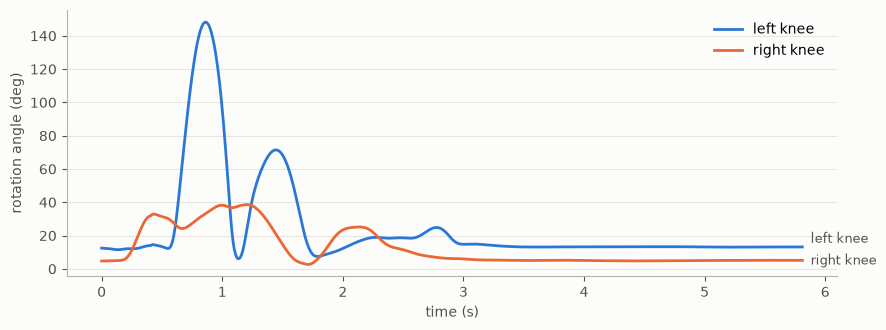

In [4]:
# 그림을 그리는 라이브러리
import matplotlib.pyplot as plt

# 그림의 기본 색과 글자 크기 정하기
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#b4b2a9', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

# 왼쪽 무릎과 오른쪽 무릎의 관절 번호
left_knee, right_knee = 4, 5
# 촬영 프레임 속도 읽기
rate = float(amass['mocap_framerate'])
# 프레임 번호를 초 단위 시간으로 바꾸기
seconds = np.arange(len(amass['poses'])) / rate
# 왼쪽 무릎의 회전값 3칸 꺼내기
left = amass['poses'][:, left_knee * 3:left_knee * 3 + 3]
# 오른쪽 무릎의 회전값 3칸 꺼내기
right = amass['poses'][:, right_knee * 3:right_knee * 3 + 3]
# 벡터의 길이가 각도이므로 길이를 구해 도(degree)로 바꾸기
left_deg, right_deg = np.degrees(np.linalg.norm(left, axis=1)), np.degrees(np.linalg.norm(right, axis=1))

# 왼쪽 무릎이 가장 많이 굽은 프레임 찾기
peak = left_deg.argmax()
# 그 프레임의 회전값과 각도 출력
print('frame', peak, '| left knee rotation (rad):', left[peak].round(3), '| angle:', round(float(left_deg[peak]), 1), 'deg')

# 그림 1개 만들기
fig, ax = plt.subplots(figsize=(9, 3.4))
# 왼쪽 무릎 각도 그리기
ax.plot(seconds, left_deg, color='#2a78d6', linewidth=2, label='left knee')
# 오른쪽 무릎 각도 그리기
ax.plot(seconds, right_deg, color='#eb6834', linewidth=2, label='right knee')
# 선 끝에 이름 적기
ax.annotate('left knee', (seconds[-1], left_deg[-1]), xytext=(6, 3), textcoords='offset points', color='#52514e', fontsize=9, annotation_clip=False)
ax.annotate('right knee', (seconds[-1], right_deg[-1]), xytext=(6, -3), textcoords='offset points', color='#52514e', fontsize=9, annotation_clip=False)
# 축 이름 적기
ax.set_xlabel('time (s)')
ax.set_ylabel('rotation angle (deg)')
# 가로 눈금선 넣기
ax.grid(axis='y', color='#e6e4dd', linewidth=0.7)
# 범례 넣기
ax.legend(frameon=False, loc='upper right')
# 여백 맞추고 그림 출력
fig.tight_layout()
plt.show()

왼발로 차는 약 1초 지점에서 왼쪽 무릎 각도가 약 150도까지 올라간다. 오른쪽 무릎은 40도를 넘지 않는다. 회전값만으로 어느 쪽 다리를 썼는지 알 수 있다.

## 6. `trans` 읽는 법

`trans`는 프레임별 몸 전체의 위치이고 단위는 미터다. AMASS는 **z축이 위쪽**이라 z가 높이, x와 y가 바닥면 위의 위치다.


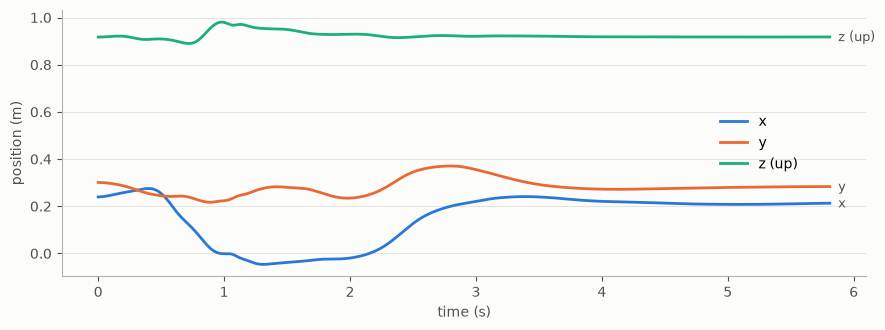

mean trans (x, y, z): [0.152 0.282 0.924]


In [5]:
# 축 이름과 색 짝 정하기
axes_info = [('x', '#2a78d6'), ('y', '#eb6834'), ('z (up)', '#1baf7a')]

# 그림 1개 만들기
fig, ax = plt.subplots(figsize=(9, 3.4))
# x, y, z를 하나씩 그리기
for i, (name, color) in enumerate(axes_info):
    # 시간에 따른 위치 그리기
    ax.plot(seconds, amass['trans'][:, i], color=color, linewidth=2, label=name)
    # 선 끝에 축 이름 적기
    ax.annotate(name, (seconds[-1], amass['trans'][-1, i]), xytext=(6, -3), textcoords='offset points', color='#52514e', fontsize=9, annotation_clip=False)
# 축 이름 적기
ax.set_xlabel('time (s)')
ax.set_ylabel('position (m)')
# 가로 눈금선 넣기
ax.grid(axis='y', color='#e6e4dd', linewidth=0.7)
# 범례 넣기
ax.legend(frameon=False, loc='center right', bbox_to_anchor=(0.93, 0.5))
# 여백 맞추고 그림 출력
fig.tight_layout()
plt.show()

# 축별 평균 출력
print('mean trans (x, y, z):', amass['trans'].mean(axis=0).round(3))

z의 평균이 약 0.92 m로 골반 높이쯤이다. 제자리에서 차는 동작이라 x, y는 약 0.3 m 범위 안에서만 움직인다.

## 7. 파라미터에서 관절 위치로

HumanML3D는 AMASS 파일을 다음과 같이 관절 위치로 바꿔 `pose_data`에 저장한다.

1. 성별에 맞는 SMPL+H 모델에 `poses`, `trans`, `betas`(앞 10개)를 넣어 관절 52개의 위치를 계산한다.
2. 약 20fps가 되도록 프레임을 일정 간격으로 건너뛴다. 간격은 `int(촬영 fps / 20)`이다.
3. 축을 바꿔 y축이 위쪽이 되게 한다. 새 y는 원래 z이고, 새 z는 원래 y다.

같은 파일의 `pose_data` 결과와 비교한다.


AMASS frames: 582 | step: 5 | expected frames: 117 | pose_data shape: (117, 52, 3)
AMASS trans mean (z up): [0.152 0.282 0.924]
pose_data pelvis mean (y up): [0.151 0.954 0.044]


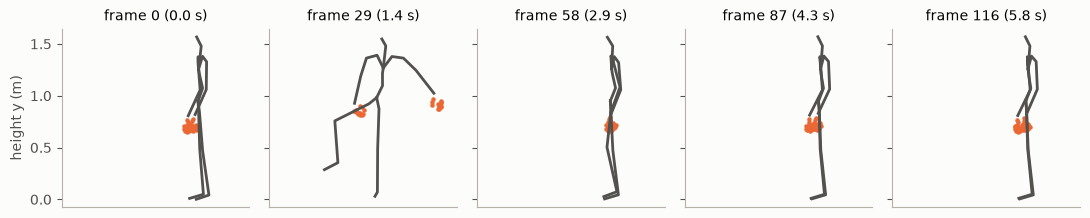

In [6]:
# 같은 모션의 pose_data 파일 열기
pose = np.load('/home/jaesik/mnt/HumanML3D/pose_data/KIT/3/kick_high_left02_poses.npy')
# 건너뛰는 간격 계산
step = int(rate / 20)
# 원본 프레임 수, 간격, 변환 후 예상 프레임 수, 실제 형태 출력
print('AMASS frames:', len(amass['poses']), '| step:', step, '| expected frames:', len(amass['poses'][::step]), '| pose_data shape:', pose.shape)
# 원본 trans의 평균 출력 (z가 높이)
print('AMASS trans mean (z up):', amass['trans'].mean(axis=0).round(3))
# 변환 후 골반 위치의 평균 출력 (y가 높이)
print('pose_data pelvis mean (y up):', pose[:, 0].mean(axis=0).round(3))

# 몸 관절을 잇는 뼈대 목록
chains = [[0, 2, 5, 8, 11], [0, 1, 4, 7, 10], [0, 3, 6, 9, 12, 15], [9, 14, 17, 19, 21], [9, 13, 16, 18, 20]]
# 동작 전체에서 5개 프레임 고르기
frames = np.linspace(0, len(pose) - 1, 5).astype(int)

# 가로로 5칸 만들기
fig, axs = plt.subplots(1, 5, figsize=(11, 3.6), sharey=True)
# 칸마다 프레임 하나씩 그리기
for ax, f in zip(axs, frames):
    # 뼈대를 하나씩 그리기 (가로 x, 세로 y)
    for chain in chains:
        ax.plot(pose[f, chain, 0], pose[f, chain, 1], color='#52514e', linewidth=2)
    # 손가락 관절 30개를 점으로 그리기
    ax.scatter(pose[f, 22:, 0], pose[f, 22:, 1], s=5, color='#eb6834')
    # 프레임 번호와 시간 적기
    ax.set_title(f'frame {f} ({f / 20:.1f} s)', fontsize=10)
    # 가로세로 비율을 같게 맞추기
    ax.set_aspect('equal')
    # 가로 범위 고정하기
    ax.set_xlim(pose[:, :, 0].min() - 0.1, pose[:, :, 0].max() + 0.1)
    # 눈금 숨기기
    ax.set_xticks([])
# 왼쪽 칸에 세로축 이름 적기
axs[0].set_ylabel('height y (m)')
# 여백 맞추고 그림 출력
fig.tight_layout()
plt.show()

`trans`와 골반 위치는 완전히 같지 않다. 인체 모델 안에서 골반이 원점에 있지 않고, 몸 방향에 따라 위치가 달라지기 때문이다. 위 출력에서 원래 y 평균(0.282)과 새 z 평균(0.044)이 다른 것이 그 예다.

그림의 주황색 점은 손가락 관절이다. HumanML3D는 이 중 몸 관절 22개만 쓴다.

## 8. HumanML3D와의 연결

| 단계 | 위치 | 형태 | 내용 |
|---|---|---|---|
| 원본 | `amass_data/*.npz` | 파라미터 | 이 노트북에서 본 파일 |
| 관절 위치 | `pose_data/*.npy` | (T, 52, 3) | 약 20fps, y축 위쪽 |
| 구간 자르기 | `joints/*.npy` | (T, 52, 3) | `index.csv` 기준으로 자르고 x 부호를 뒤집음 |
| 최종 | `HumanML3D/new_joints/*.npy` | (T, 22, 3) | 몸 22관절, 표준 골격, 바닥과 시작 위치 정렬 |

`index.csv`는 어느 원본의 몇 프레임이 어떤 클립이 되는지 적은 표다. 프레임 번호는 20fps 기준이다. 데이터셋별로 몇 개 파일이 실제로 쓰였는지 센다.


In [7]:
# 원본과 클립의 대응표 읽기
index = pd.read_csv('/home/jaesik/mnt/HumanML3D/index.csv')
# 원본 경로에서 데이터셋 이름 뽑기
index['dataset'] = index['source_path'].str.split('/').str[2]
# HumanAct12를 빼고 AMASS 행만 고르기
used = index[index['dataset'] != 'humanact12']

# 표의 행을 담을 목록
rows = []
# 데이터셋을 하나씩 꺼내기
for d in datasets:
    # 이 데이터셋에서 쓰인 행만 고르기
    part = used[used['dataset'] == d]
    # 모션 파일 수, 쓰인 파일 수, 만들어진 클립 수 추가
    rows.append({'dataset': d, 'motion files': sum(os.path.basename(f) != 'shape.npz' for f in files[d]), 'files used': part['source_path'].nunique(), 'clips': len(part)})

# 표 만들기
usage = pd.DataFrame(rows).sort_values('clips', ascending=False).reset_index(drop=True)
# 합계 출력
print(usage['motion files'].sum(), 'motion files ->', usage['files used'].sum(), 'files used ->', usage['clips'].sum(), 'clips')
# 표 출력
usage

13943 motion files -> 10524 files used -> 13425 clips


,dataset,motion files,files used,clips
0,KIT,4232,4232,4648
1,CMU,2082,2082,2913
2,BMLmovi,1801,1801,1839
3,Eyes_Japan_Dataset,750,749,1465
4,MPI_HDM05,215,204,771
5,BioMotionLab_NTroje,3061,306,373
6,EKUT,349,349,351
7,ACCAD,252,252,277
8,DFaust_67,129,129,135
9,MPI_Limits,35,35,132


한 파일을 여러 구간으로 잘라 클립 여러 개를 만들기도 하고, 쓰이지 않는 파일도 있다. 클립 수는 좌우 반전본을 뺀 값이다.

In [8]:
# 첫 번째 클립의 원본과 구간 출력
print(index.loc[0, ['source_path', 'start_frame', 'end_frame', 'new_name']].to_dict())
# 단계별 파일 경로
stages = {'pose_data': '/home/jaesik/mnt/HumanML3D/pose_data/KIT/3/kick_high_left02_poses.npy', 'joints': '/home/jaesik/mnt/HumanML3D/joints/000000.npy', 'new_joints': '/home/jaesik/mnt/HumanML3D/HumanML3D/new_joints/000000.npy'}
# 단계별로 형태 출력
for name, path in stages.items():
    # 파일을 열어 형태 출력
    print(f'{name:12}{np.load(path).shape}')

{'source_path': './pose_data/KIT/3/kick_high_left02_poses.npy', 'start_frame': 0, 'end_frame': 117, 'new_name': '000000.npy'}
pose_data   (117, 52, 3)
joints      (117, 52, 3)
new_joints  (116, 22, 3)


최종 파일이 `joints`보다 1프레임 짧은 이유는 263차원 특징이 다음 프레임과의 차이(속도)를 쓰기 때문이다.